In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
import time
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    average_precision_score,
)

In [34]:
train_path="/content/drive/MyDrive/Reliable-Chest-X-Ray-AI/merged_datasets/train_merged.csv"
test_path="/content/drive/MyDrive/Reliable-Chest-X-Ray-AI/merged_datasets/test_merged.csv"
val_path="/content/drive/MyDrive/Reliable-Chest-X-Ray-AI/merged_datasets/validation_merged.csv"
df_train=pd.read_csv(train_path)
df_test=pd.read_csv(test_path)
df_val=pd.read_csv(val_path)

In [35]:
df_train.columns

Index(['image_name', 'follow_up', 'patient_age', 'patient_sex',
       'view_position', 'label', 'embedding_0', 'embedding_1', 'embedding_2',
       'embedding_3',
       ...
       'embedding_1014', 'embedding_1015', 'embedding_1016', 'embedding_1017',
       'embedding_1018', 'embedding_1019', 'embedding_1020', 'embedding_1021',
       'embedding_1022', 'embedding_1023'],
      dtype='object', length=1030)

In [43]:
excluded=['image_name', 'follow_up', 'patient_age', 'patient_sex','view_position']
df_train.drop(columns=excluded,inplace=True)
df_test.drop(columns=excluded,inplace=True)
df_val.drop(columns=excluded,inplace=True)
df_train.columns

Index(['label', 'embedding_0', 'embedding_1', 'embedding_2', 'embedding_3',
       'embedding_4', 'embedding_5', 'embedding_6', 'embedding_7',
       'embedding_8',
       ...
       'embedding_1014', 'embedding_1015', 'embedding_1016', 'embedding_1017',
       'embedding_1018', 'embedding_1019', 'embedding_1020', 'embedding_1021',
       'embedding_1022', 'embedding_1023'],
      dtype='object', length=1025)

In [44]:
X_train=df_train.drop(columns=['label'])
y_train=df_train['label']
X_test=df_test.drop(columns=['label'])
y_test=df_test['label']
X_val=df_val.drop(columns=['label'])
y_val=df_val['label']


In [37]:
X_train.shape,y_train.shape,X_test.shape,y_test.shape,X_val.shape,y_val.shape

((14000, 1029), (14000,), (3000, 1029), (3000,), (3000, 1029), (3000,))

In [10]:
C_values = [0.01, 0.1, 1, 10]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

results = []

start = time.time()
total = len(C_values) * 3
done = 0

for C in C_values:
    scores = []

    for train_idx, val_idx in cv.split(X_train, y_train):

        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=C,
                max_iter=1000,
                random_state=42
            )
        )

        model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

        pred = model.predict(X_train.iloc[val_idx])

        score = f1_score(y_train.iloc[val_idx], pred)
        scores.append(score)

        done += 1

        elapsed = time.time() - start
        eta = (elapsed / done) * (total - done)

        print(
            f"{done}/{total} | "
            f"C={C} | "
            f"F1={score:.4f} | "
            f"ETA: {eta/60:.1f} min"
        )

    mean_score = np.mean(scores)
    results.append((C, mean_score))

    print(f"--> C={C} | Mean F1={mean_score:.4f}\n")

best_C, best_f1 = max(results, key=lambda x: x[1])

print("=" * 40)
print(f"Best C: {best_C}")
print(f"Best CV F1: {best_f1:.4f}")
print("=" * 40)

1/12 | C=0.01 | F1=0.6876 | ETA: 0.7 min
2/12 | C=0.01 | F1=0.6984 | ETA: 0.5 min
3/12 | C=0.01 | F1=0.6833 | ETA: 0.4 min
--> C=0.01 | Mean F1=0.6898

4/12 | C=0.1 | F1=0.6731 | ETA: 0.5 min
5/12 | C=0.1 | F1=0.6861 | ETA: 0.5 min
6/12 | C=0.1 | F1=0.6716 | ETA: 0.4 min
--> C=0.1 | Mean F1=0.6769

7/12 | C=1 | F1=0.6683 | ETA: 0.4 min
8/12 | C=1 | F1=0.6790 | ETA: 0.4 min
9/12 | C=1 | F1=0.6658 | ETA: 0.3 min
--> C=1 | Mean F1=0.6710

10/12 | C=10 | F1=0.6659 | ETA: 0.3 min


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


11/12 | C=10 | F1=0.6760 | ETA: 0.2 min
12/12 | C=10 | F1=0.6619 | ETA: 0.0 min
--> C=10 | Mean F1=0.6679

Best C: 0.01
Best CV F1: 0.6898


In [13]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=0.01,
        penalty="l2",
        solver="liblinear",
        max_iter=3000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

print("\nModel Configuration:")
print("C:", 0.01)
print("Penalty:", "l2")
print("Solver:", "liblinear")
print("Max Iterations:", 3000)

Logistic Regression model trained successfully.

Model Configuration:
C: 0.01
Penalty: l2
Solver: liblinear
Max Iterations: 3000


In [19]:
model_path = "/content/drive/MyDrive/Reliable-Chest-X-Ray-AI/models/logistic_regression_model.joblib"

joblib.dump(logistic_model, model_path)

print("Model saved successfully.")
print(model_path)

Model saved successfully.
/content/drive/MyDrive/Reliable-Chest-X-Ray-AI/models/logistic_regression_model.joblib


## Embedding and Feature Integration

For this experiment, we will use the **pretrained image embeddings combined with additional metadata features** as the input to the Logistic Regression model.

The model input will therefore consist of:

- **1024-dimensional image embeddings**
- **Patient and examination metadata features**

In [38]:
train_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)
val_data = pd.read_csv(val_path)

In [39]:
excluded = ['image_name']
train_data.drop(columns=excluded, inplace=True)
test_data.drop(columns=excluded, inplace=True)
val_data.drop(columns=excluded, inplace=True)

In [46]:
X_train_m=train_data.drop(columns=['label'])
y_train_m=train_data['label']
X_test_m=test_data.drop(columns=['label'])
y_test_m=test_data['label']
X_val_m=val_data.drop(columns=['label'])
y_val_m=val_data['label']


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

embedding_features = [col for col in X_train.columns if col.startswith("embedding_")]

numerical_features = [
    "follow_up",
    "patient_age"
]

categorical_features = [
    "patient_sex",
    "view_position"
]

preprocessor = ColumnTransformer([
    ("embeddings", StandardScaler(), embedding_features),
    ("numerical", StandardScaler(), numerical_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=0.01,
        penalty="l2",
        solver="liblinear",
        max_iter=3000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

print("\nModel Configuration:")
print("C:", 0.01)
print("Penalty:", "l2")
print("Solver:", "liblinear")
print("Max Iterations:", 3000)

Logistic Regression model trained successfully.

Model Configuration:
C: 0.01
Penalty: l2
Solver: liblinear
Max Iterations: 3000


In [28]:
model_path = "/content/drive/MyDrive/Reliable-Chest-X-Ray-AI/models/logistic_regression_embeddings_metadata.joblib"

joblib.dump(logistic_model, model_path)

print("Model saved successfully.")
print(model_path)

Model saved successfully.
/content/drive/MyDrive/Reliable-Chest-X-Ray-AI/models/logistic_regression_embeddings_metadata.joblib


## Evaluation

In [29]:
embeddings_model = joblib.load(
    "/content/drive/MyDrive/Reliable-Chest-X-Ray-AI/models/logistic_regression_model.joblib"
)

metadata_model = joblib.load(
    "/content/drive/MyDrive/Reliable-Chest-X-Ray-AI/models/logistic_regression_embeddings_metadata.joblib"
)

print("Both models loaded successfully.")

Both models loaded successfully.


In [47]:
X_val.columns

Index(['embedding_0', 'embedding_1', 'embedding_2', 'embedding_3',
       'embedding_4', 'embedding_5', 'embedding_6', 'embedding_7',
       'embedding_8', 'embedding_9',
       ...
       'embedding_1014', 'embedding_1015', 'embedding_1016', 'embedding_1017',
       'embedding_1018', 'embedding_1019', 'embedding_1020', 'embedding_1021',
       'embedding_1022', 'embedding_1023'],
      dtype='object', length=1024)

In [48]:
y_val_prob_embeddings = embeddings_model.predict_proba(X_val)[:, 1]

y_val_prob_metadata = metadata_model.predict_proba(X_val_m)[:, 1]

print("Validation probabilities generated successfully.")

Validation probabilities generated successfully.


In [50]:
import numpy as np
import pandas as pd

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:
    y_pred_embeddings = (y_val_prob_embeddings >= threshold).astype(int)
    y_pred_metadata = (y_val_prob_metadata >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "model": "Embeddings Only",
        "precision": precision_score(y_val, y_pred_embeddings),
        "recall": recall_score(y_val, y_pred_embeddings),
        "specificity": recall_score(y_val, y_pred_embeddings, pos_label=0),
        "f1": f1_score(y_val, y_pred_embeddings)
    })

    threshold_results.append({
        "threshold": threshold,
        "model": "Embeddings + Metadata",
        "precision": precision_score(y_val_m, y_pred_metadata),
        "recall": recall_score(y_val_m, y_pred_metadata),
        "specificity": recall_score(y_val_m, y_pred_metadata, pos_label=0),
        "f1": f1_score(y_val_m, y_pred_metadata)
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results

,threshold,model,precision,recall,specificity,f1
0,0.10,Embeddings Only,0.511676,0.993333,0.052000,0.675431
1,0.10,Embeddings + Metadata,0.512565,0.992667,0.056000,0.676050
2,0.15,Embeddings Only,0.531034,0.975333,0.138667,0.687662
3,0.15,Embeddings + Metadata,0.531807,0.975333,0.141333,0.688309
4,0.20,Embeddings Only,0.553474,0.945333,0.237333,0.698178
5,0.20,Embeddings + Metadata,0.555729,0.947333,0.242667,0.700518
6,0.25,Embeddings Only,0.578171,0.914667,0.332667,0.708495
7,0.25,Embeddings + Metadata,0.577721,0.909333,0.335333,0.706553
8,0.30,Embeddings Only,0.609448,0.868667,0.443333,0.716328
9,0.30,Embeddings + Metadata,0.609265,0.868000,0.443333,0.715975


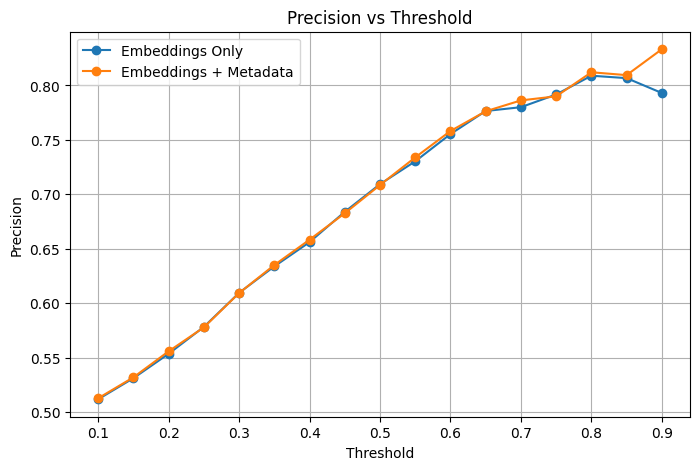

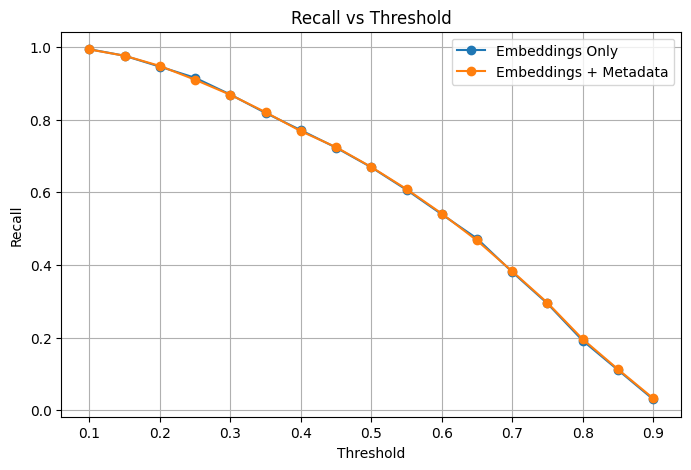

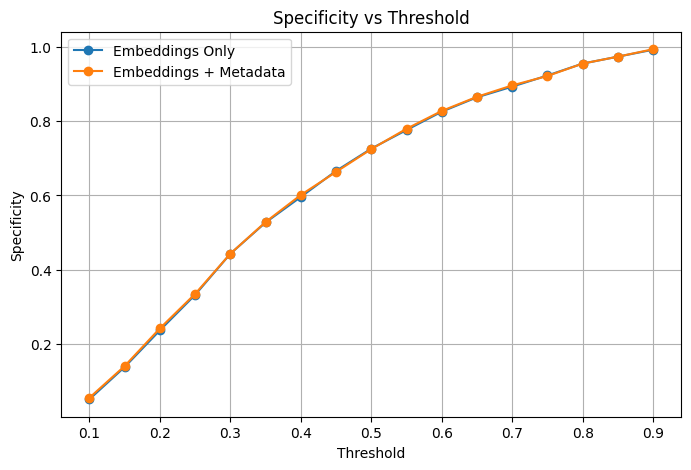

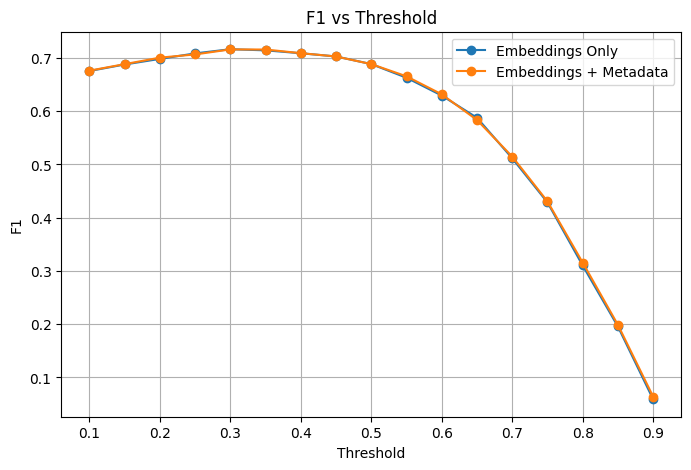

In [51]:
metrics = ["precision", "recall", "specificity", "f1"]

for metric in metrics:
    plt.figure(figsize=(8, 5))

    for model in threshold_results["model"].unique():
        model_results = threshold_results[
            threshold_results["model"] == model
        ]

        plt.plot(
            model_results["threshold"],
            model_results[metric],
            marker="o",
            label=model
        )

    plt.xlabel("Threshold")
    plt.ylabel(metric.capitalize())
    plt.title(f"{metric.capitalize()} vs Threshold")
    plt.legend()
    plt.grid(True)
    plt.show()

In [52]:
thresholds_fine = np.arange(0.25, 0.351, 0.01)

fine_results = []

for threshold in thresholds_fine:
    y_pred_embeddings = (y_val_prob_embeddings >= threshold).astype(int)
    y_pred_metadata = (y_val_prob_metadata >= threshold).astype(int)

    fine_results.append({
        "threshold": threshold,
        "model": "Embeddings Only",
        "precision": precision_score(y_val, y_pred_embeddings),
        "recall": recall_score(y_val, y_pred_embeddings),
        "specificity": recall_score(y_val, y_pred_embeddings, pos_label=0),
        "f1": f1_score(y_val, y_pred_embeddings)
    })

    fine_results.append({
        "threshold": threshold,
        "model": "Embeddings + Metadata",
        "precision": precision_score(y_val_m, y_pred_metadata),
        "recall": recall_score(y_val_m, y_pred_metadata),
        "specificity": recall_score(y_val_m, y_pred_metadata, pos_label=0),
        "f1": f1_score(y_val_m, y_pred_metadata)
    })

fine_results = pd.DataFrame(fine_results)

fine_results.sort_values(
    ["model", "f1"],
    ascending=[True, False]
).head(10)

,threshold,model,precision,recall,specificity,f1
15,0.32,Embeddings + Metadata,0.619048,0.849333,0.477333,0.716133
11,0.30,Embeddings + Metadata,0.609265,0.868000,0.443333,0.715975
13,0.31,Embeddings + Metadata,0.614027,0.858000,0.460667,0.715795
21,0.35,Embeddings + Metadata,0.635003,0.820000,0.528667,0.715740
19,0.34,Embeddings + Metadata,0.628788,0.830000,0.510000,0.715517
17,0.33,Embeddings + Metadata,0.623145,0.840000,0.492000,0.715503
7,0.28,Embeddings + Metadata,0.599099,0.886667,0.406667,0.715054
9,0.29,Embeddings + Metadata,0.603306,0.876000,0.424000,0.714519
5,0.27,Embeddings + Metadata,0.591009,0.894000,0.381333,0.711595
3,0.26,Embeddings + Metadata,0.585640,0.902667,0.361333,0.710388


In [53]:
embeddings_only_results = fine_results[
    fine_results["model"] == "Embeddings Only"
].sort_values("f1", ascending=False)

embeddings_only_results.head(10)

,threshold,model,precision,recall,specificity,f1
8,0.29,Embeddings Only,0.604577,0.880667,0.424000,0.716961
10,0.30,Embeddings Only,0.609448,0.868667,0.443333,0.716328
14,0.32,Embeddings Only,0.617918,0.850667,0.474000,0.715849
16,0.33,Embeddings Only,0.624441,0.838000,0.496000,0.715628
6,0.28,Embeddings Only,0.598022,0.886667,0.404000,0.714286
20,0.35,Embeddings Only,0.633781,0.818000,0.527333,0.714203
18,0.34,Embeddings Only,0.628296,0.826000,0.511333,0.713710
12,0.31,Embeddings Only,0.611032,0.856667,0.454667,0.713294
4,0.27,Embeddings Only,0.590150,0.894667,0.378667,0.711182
2,0.26,Embeddings Only,0.584735,0.904000,0.358000,0.710134


## Selected Classification Thresholds

The classification threshold was selected based on the **maximum F1 Score achieved on the validation set**.

### Logistic Regression — Embeddings Only

- **Selected Threshold:** `0.29`
- **Selection Criterion:** Maximum Validation F1
- **Validation F1:** `0.71696`

### Logistic Regression — Embeddings + Metadata

- **Selected Threshold:** `0.32`
- **Selection Criterion:** Maximum Validation F1
- **Validation F1:** `0.71613`

In [54]:
y_val_pred_embeddings = (y_val_prob_embeddings >= 0.29).astype(int)
y_val_pred_metadata = (y_val_prob_metadata >= 0.32).astype(int)

print("Validation predictions generated using selected thresholds.")

Validation predictions generated using selected thresholds.


In [57]:
results = []

for model_name, y_true, y_prob, y_pred in [
    (
        "Embeddings Only",
        y_val,
        y_val_prob_embeddings,
        y_val_pred_embeddings
    ),
    (
        "Embeddings + Metadata",
        y_val_m,
        y_val_prob_metadata,
        y_val_pred_metadata
    )
]:
    cm = confusion_matrix(y_true, y_pred)

    tn, fp, fn, tp = cm.ravel()

    results.append({
        "Model": model_name,
        "Threshold": 0.29 if model_name == "Embeddings Only" else 0.32,
        "AUROC": roc_auc_score(y_true, y_prob),
        "AUPRC": average_precision_score(y_true, y_prob),
        "Precision": precision_score(y_true, y_pred),
        "Sensitivity": recall_score(y_true, y_pred),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(y_true, y_pred)
    })

validation_results = pd.DataFrame(results)

validation_results

,Model,Threshold,AUROC,AUPRC,Precision,Sensitivity,Specificity,F1
0,Embeddings Only,0.29,0.754161,0.730844,0.604577,0.880667,0.424000,0.716961
1,Embeddings + Metadata,0.32,0.755116,0.730933,0.619048,0.849333,0.477333,0.716133


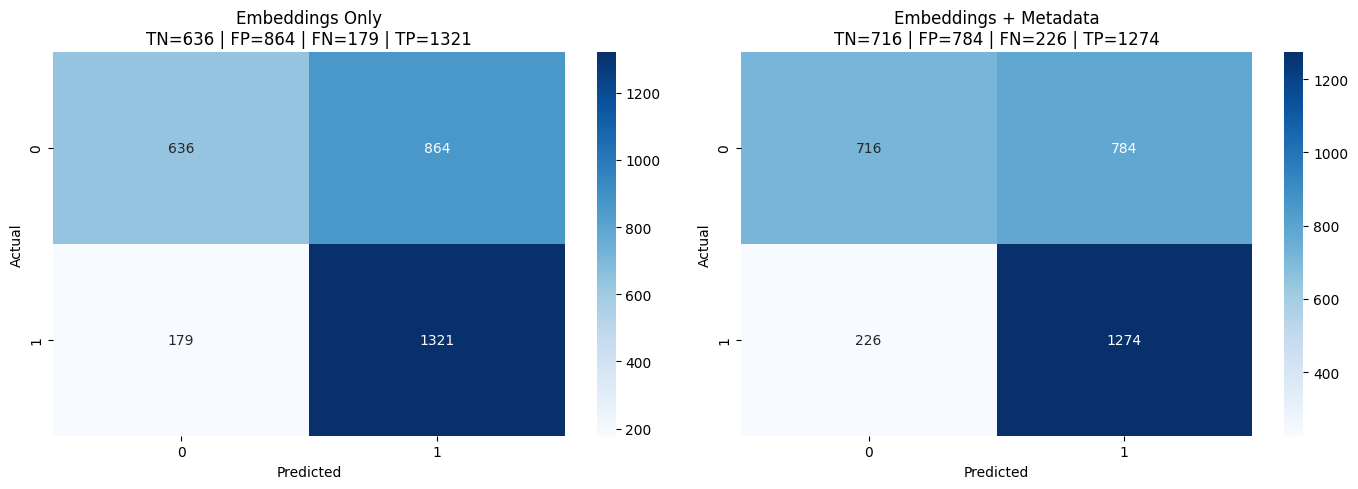

In [60]:
cm_embeddings = confusion_matrix(
    y_val,
    y_val_pred_embeddings
)

cm_metadata = confusion_matrix(
    y_val_m,
    y_val_pred_metadata
)

tn_e, fp_e, fn_e, tp_e = cm_embeddings.ravel()
tn_m, fp_m, fn_m, tp_m = cm_metadata.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm_embeddings,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title(
    f"Embeddings Only\n"
    f"TN={tn_e} | FP={fp_e} | FN={fn_e} | TP={tp_e}"
)

axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_metadata,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1]
)

axes[1].set_title(
    f"Embeddings + Metadata\n"
    f"TN={tn_m} | FP={fp_m} | FN={fn_m} | TP={tp_m}"
)

axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [61]:
from sklearn.metrics import classification_report

print("=== Embeddings Only ===")
print(
    classification_report(
        y_val,
        y_val_pred_embeddings,
        digits=4
    )
)

print("\n=== Embeddings + Metadata ===")
print(
    classification_report(
        y_val_m,
        y_val_pred_metadata,
        digits=4
    )
)

=== Embeddings Only ===
              precision    recall  f1-score   support

           0     0.7804    0.4240    0.5495      1500
           1     0.6046    0.8807    0.7170      1500

    accuracy                         0.6523      3000
   macro avg     0.6925    0.6523    0.6332      3000
weighted avg     0.6925    0.6523    0.6332      3000


=== Embeddings + Metadata ===
              precision    recall  f1-score   support

           0     0.7601    0.4773    0.5864      1500
           1     0.6190    0.8493    0.7161      1500

    accuracy                         0.6633      3000
   macro avg     0.6896    0.6633    0.6513      3000
weighted avg     0.6896    0.6633    0.6513      3000

